In [1]:
%%writefile ../src/models.py
from dataclasses import dataclass
import numpy as np


@dataclass
class RLParams:
    beta: float = 3.0
    alpha_c_pos: float = 0.5
    alpha_c_neg: float = 0.15
    alpha_u_pos: float = 0.15
    alpha_u_neg: float = 0.5
    perseveration: float = 0.0

    @classmethod
    def from_confirmation(
        cls,
        beta: float,
        alpha_con: float,
        alpha_dis: float,
        perseveration: float = 0.0,
    ) -> "RLParams":
        """Confirmation parameterization:
        - Chosen + (PE_c > 0) and Unchosen - (PE_u < 0) use alpha_con
        - Chosen - (PE_c < 0) and Unchosen + (PE_u > 0) use alpha_dis
        """
        return cls(
            beta=beta,
            alpha_c_pos=alpha_con,
            alpha_c_neg=alpha_dis,
            alpha_u_pos=alpha_dis,
            alpha_u_neg=alpha_con,
            perseveration=perseveration,
        )


def softmax_choice_prob(
    q_values: np.ndarray,
    beta: float,
    prev_choice: int | None = None,
    pi: float = 0.0,
) -> np.ndarray:
    """Compute choice probabilities over actions (shape: [n_actions])."""
    logits = beta * np.asarray(q_values, dtype=float)
    if prev_choice is not None and pi != 0.0:
        logits[prev_choice] += pi
    logits = logits - np.max(logits)
    exp_logits = np.exp(logits)
    return exp_logits / np.sum(exp_logits)


def update_q_values(
    q_values: np.ndarray,
    choice: int,
    r_chosen: float,
    r_unchosen: float | None,
    params: RLParams,
    counterfactual: bool = True,
) -> tuple[np.ndarray, dict[str, float]]:
    """Update Q-values for one trial in a 2-option context."""
    q_next = np.array(q_values, dtype=float, copy=True)
    unchosen = 1 - choice

    pe_c = float(r_chosen) - q_next[choice]
    lr_c = params.alpha_c_pos if pe_c >= 0 else params.alpha_c_neg
    q_next[choice] = q_next[choice] + lr_c * pe_c

    info = {"pe_c": pe_c, "lr_c": lr_c}

    if counterfactual and r_unchosen is not None:
        pe_u = float(r_unchosen) - q_next[unchosen]
        lr_u = params.alpha_u_pos if pe_u >= 0 else params.alpha_u_neg
        q_next[unchosen] = q_next[unchosen] + lr_u * pe_u
        info.update({"pe_u": pe_u, "lr_u": lr_u})

    return q_next, info

Overwriting ../src/models.py


In [2]:
%%writefile ../src/simulate.py
import numpy as np
import pandas as pd

from src.models import RLParams, softmax_choice_prob, update_q_values


def generate_session_contexts(
    rng: np.random.Generator,
    n_trials_per_context: int = 24,
) -> list[dict]:
    """Generate the 4 contexts (24 trials each = 96 trials) for one session."""
    half = n_trials_per_context // 2
    contexts = []

    p_sym = np.full((n_trials_per_context, 2), 0.5)
    contexts.append({
        "condition": "symmetric",
        "context_idx": 0,
        "p_reward": p_sym,
        "best_action_first_half": None,
        "best_action_second_half": None,
    })

    for asym_idx in range(2):
        best_opt = int(rng.integers(0, 2))
        p_asym = np.full((n_trials_per_context, 2), 0.25)
        p_asym[:, best_opt] = 0.75
        contexts.append({
            "condition": "asymmetric",
            "context_idx": 1 + asym_idx,
            "p_reward": p_asym,
            "best_action_first_half": best_opt,
            "best_action_second_half": best_opt,
        })

    init_best = int(rng.integers(0, 2))
    other_opt = 1 - init_best
    p_rev = np.zeros((n_trials_per_context, 2))
    p_rev[:half, init_best] = 0.83
    p_rev[:half, other_opt] = 0.17
    p_rev[half:, init_best] = 0.17
    p_rev[half:, other_opt] = 0.83
    contexts.append({
        "condition": "reversal",
        "context_idx": 3,
        "p_reward": p_rev,
        "best_action_first_half": init_best,
        "best_action_second_half": other_opt,
    })

    rng.shuffle(contexts)
    for order_idx, ctx in enumerate(contexts):
        ctx["context_order"] = order_idx
    return contexts


def simulate_participant(
    participant_id: int,
    params: RLParams,
    experiment: int = 2,
    n_sessions: int = 2,
    n_trials_per_context: int = 24,
    seed: int | None = None,
) -> pd.DataFrame:
    """Simulate one virtual participant across 2 sessions x 4 contexts x 24 trials (192 trials)."""
    if experiment not in (1, 2):
        raise ValueError("experiment must be 1 (partial feedback) or 2 (complete feedback).")

    rng = np.random.default_rng(seed)
    counterfactual = experiment == 2
    half = n_trials_per_context // 2
    rows = []
    global_trial = 0

    for session in range(1, n_sessions + 1):
        contexts = generate_session_contexts(rng, n_trials_per_context=n_trials_per_context)
        for ctx in contexts:
            q_values = np.zeros(2, dtype=float)
            prev_choice: int | None = None
            p_reward = ctx["p_reward"]

            for t in range(n_trials_per_context):
                global_trial += 1
                probs = softmax_choice_prob(
                    q_values=q_values,
                    beta=params.beta,
                    prev_choice=prev_choice,
                    pi=params.perseveration,
                )
                choice = int(rng.choice(2, p=probs))
                unchosen = 1 - choice

                r0 = 1.0 if rng.random() < p_reward[t, 0] else -1.0
                r1 = 1.0 if rng.random() < p_reward[t, 1] else -1.0
                outcomes = np.array([r0, r1], dtype=float)

                r_chosen = float(outcomes[choice])
                r_unchosen = float(outcomes[unchosen]) if counterfactual else np.nan

                phase = "first_half" if t < half else "second_half"
                if ctx["condition"] == "asymmetric":
                    is_correct = int(choice == ctx["best_action_first_half"])
                elif ctx["condition"] == "reversal":
                    target = ctx["best_action_first_half"] if t < half else ctx["best_action_second_half"]
                    is_correct = int(choice == target)
                else:
                    is_correct = np.nan

                q_next, pe_info = update_q_values(
                    q_values=q_values,
                    choice=choice,
                    r_chosen=r_chosen,
                    r_unchosen=None if not counterfactual else r_unchosen,
                    params=params,
                    counterfactual=counterfactual,
                )

                rows.append({
                    "participant_id": participant_id,
                    "experiment": experiment,
                    "session": session,
                    "context_order": ctx["context_order"],
                    "condition": ctx["condition"],
                    "phase": phase,
                    "trial_in_context": t + 1,
                    "global_trial": global_trial,
                    "choice": choice,
                    "unchosen": unchosen,
                    "r_chosen": r_chosen,
                    "r_unchosen": r_unchosen,
                    "p_choice_0": probs[0],
                    "p_choice_1": probs[1],
                    "q_0_before": q_values[0],
                    "q_1_before": q_values[1],
                    "is_correct": is_correct,
                    "pe_c": pe_info["pe_c"],
                    "pe_u": pe_info.get("pe_u", np.nan),
                })

                q_values = q_next
                prev_choice = choice

    return pd.DataFrame(rows)


def simulate_cohort(
    param_list: list[RLParams],
    experiment: int = 2,
    base_seed: int = 42,
) -> pd.DataFrame:
    """Simulate a cohort of participants given a list of RLParams."""
    dfs = []
    for idx, p in enumerate(param_list):
        df_sub = simulate_participant(
            participant_id=idx + 1,
            params=p,
            experiment=experiment,
            seed=base_seed + idx,
        )
        dfs.append(df_sub)
    return pd.concat(dfs, ignore_index=True)

Overwriting ../src/simulate.py


In [3]:
import sys
from pathlib import Path
import numpy as np

# Ensure project root is on sys.path when running from notebooks/
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models import RLParams
from src.simulate import simulate_cohort

# Simulate 20 confirmation-biased agents in Experiment 2
biased_agents = [
    RLParams.from_confirmation(beta=3.0, alpha_con=0.55, alpha_dis=0.15)
    for _ in range(20)
]
df_sim = simulate_cohort(biased_agents, experiment=2, base_seed=118)

print("Total rows:", len(df_sim))
print("Trials per participant:", df_sim.groupby("participant_id").size().unique())
print("\nMean accuracy by condition & phase:")
print(
    df_sim.dropna(subset=["is_correct"])
    .groupby(["condition", "phase"])["is_correct"]
    .mean()
    .unstack()
)

Total rows: 3840
Trials per participant: [192]

Mean accuracy by condition & phase:
phase       first_half  second_half
condition                          
asymmetric    0.807292     0.963542
reversal      0.860417     0.562500


Matplotlib is building the font cache; this may take a moment.


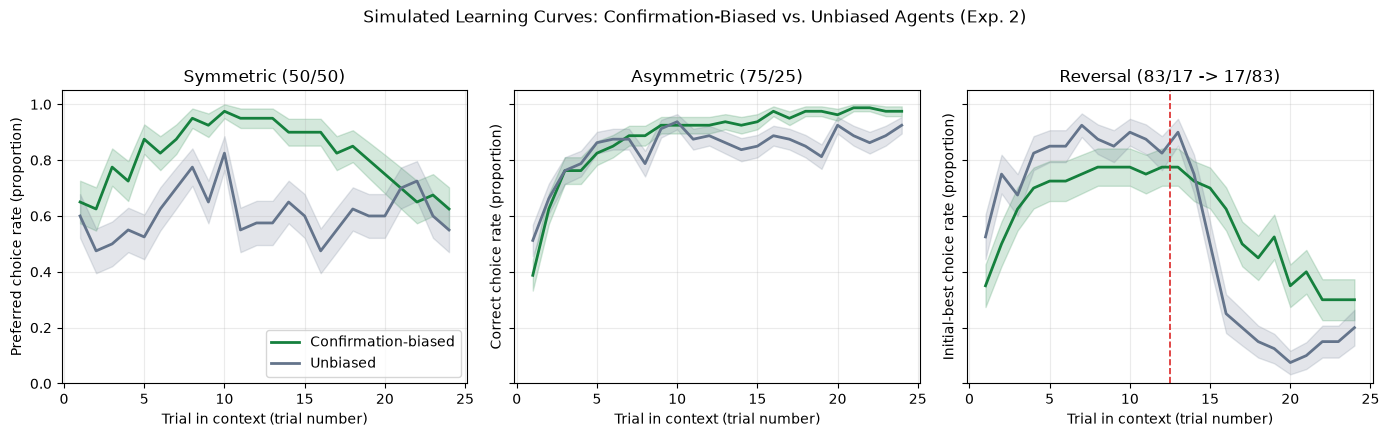

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# Simulate an unbiased comparison cohort (alpha_con == alpha_dis)
unbiased_agents = [
    RLParams.from_confirmation(beta=3.0, alpha_con=0.35, alpha_dis=0.35)
    for _ in range(20)
]
df_unbiased = simulate_cohort(unbiased_agents, experiment=2, base_seed=218)

df_sim["agent_type"] = "Confirmation-biased"
df_unbiased["agent_type"] = "Unbiased"
df_both = pd.concat([df_sim, df_unbiased], ignore_index=True)

# 1. Trial-by-trial curves per condition:
# - symmetric: preferred choice rate (choice rate of the option chosen >50% per participant/context)
# - asymmetric: correct choice rate
# - reversal: choice rate of the initially advantageous option (first-half best action)
curve_rows = []
for (agent_type, condition, pid, session, context_order), grp in df_both.groupby(
    ["agent_type", "condition", "participant_id", "session", "context_order"]
):
    grp = grp.sort_values("trial_in_context")
    if condition == "symmetric":
        counts = grp["choice"].value_counts()
        pref_opt = int(counts.idxmax())
        rate = (grp["choice"] == pref_opt).astype(float).values
    elif condition == "asymmetric":
        rate = grp["is_correct"].astype(float).values
    else:  # reversal: track initial first-half best choice across all 24 trials
        init_opt = int(grp.loc[grp["trial_in_context"] <= 12, "choice"].mode().iloc[0])
        # Better yet, use true first-half target if available; here compare choice to initial best
        first_half_best = grp.loc[grp["trial_in_context"] <= 12]
        # Infer initial best action from reward rate in first half
        r0_mean = first_half_best.loc[first_half_best["choice"] == 0, "r_chosen"].mean()
        r1_mean = first_half_best.loc[first_half_best["choice"] == 1, "r_chosen"].mean()
        init_best = 0 if (pd.notna(r0_mean) and pd.notna(r1_mean) and r0_mean >= r1_mean) else 1
        rate = (grp["choice"] == init_best).astype(float).values

    for t_val, r_val in zip(grp["trial_in_context"].values, rate):
        curve_rows.append({
            "agent_type": agent_type,
            "condition": condition,
            "trial_in_context": int(t_val),
            "choice_rate": float(r_val),
        })

df_curves = pd.DataFrame(curve_rows)
mean_curves = (
    df_curves.groupby(["agent_type", "condition", "trial_in_context"])["choice_rate"]
    .agg(["mean", "sem"])
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
panels = [
    ("symmetric", "Symmetric (50/50)", "Preferred choice rate (proportion)"),
    ("asymmetric", "Asymmetric (75/25)", "Correct choice rate (proportion)"),
    ("reversal", "Reversal (83/17 -> 17/83)", "Initial-best choice rate (proportion)"),
]

for ax, (cond, title, ylabel) in zip(axes, panels):
    for label, color in [("Confirmation-biased", "#15803d"), ("Unbiased", "#64748b")]:
        sub = mean_curves[(mean_curves["agent_type"] == label) & (mean_curves["condition"] == cond)]
        ax.plot(sub["trial_in_context"], sub["mean"], label=label, color=color, linewidth=2)
        ax.fill_between(
            sub["trial_in_context"],
            sub["mean"] - sub["sem"],
            sub["mean"] + sub["sem"],
            color=color,
            alpha=0.18,
        )
    if cond == "reversal":
        ax.axvline(12.5, color="#dc2626", linestyle="--", linewidth=1.2, label="Reversal (trial 12)")
    ax.set_title(title)
    ax.set_xlabel("Trial in context (trial number)")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0.0, 1.05)
    ax.grid(alpha=0.25)

axes[0].legend(loc="lower right", frameon=True)
fig.suptitle("Simulated Learning Curves: Confirmation-Biased vs. Unbiased Agents (Exp. 2)", y=1.03, fontsize=12)
plt.tight_layout()
fig.savefig(project_root / "figures" / "simulated_learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
%%writefile ../src/recovery.py
import numpy as np
import pandas as pd
from scipy.optimize import minimize

from src.models import RLParams, softmax_choice_prob, update_q_values


MODEL_PARAM_COUNTS = {
    "one": 2,           # beta, alpha
    "valence": 3,       # beta, alpha_pos, alpha_neg
    "information": 3,   # beta, alpha_c, alpha_u (in exp 2; 2 in exp 1)
    "confirmation": 3,  # beta, alpha_con, alpha_dis
    "full": 5,          # beta, alpha_c_pos, alpha_c_neg, alpha_u_pos, alpha_u_neg (3 in exp 1)
    "perseveration": 4, # beta, alpha_con, alpha_dis, pi
}


def vector_to_params(theta: np.ndarray, model_name: str, counterfactual: bool = True) -> RLParams:
    """Map an unconstrained/bounded optimizer vector theta to RLParams."""
    if model_name == "one":
        beta, alpha = float(theta[0]), float(theta[1])
        return RLParams(
            beta=beta,
            alpha_c_pos=alpha,
            alpha_c_neg=alpha,
            alpha_u_pos=alpha,
            alpha_u_neg=alpha,
            perseveration=0.0,
        )
    if model_name == "valence":
        beta, a_pos, a_neg = float(theta[0]), float(theta[1]), float(theta[2])
        return RLParams(
            beta=beta,
            alpha_c_pos=a_pos,
            alpha_c_neg=a_neg,
            alpha_u_pos=a_pos,
            alpha_u_neg=a_neg,
            perseveration=0.0,
        )
    if model_name == "information":
        beta, a_c = float(theta[0]), float(theta[1])
        a_u = float(theta[2]) if counterfactual and len(theta) > 2 else a_c
        return RLParams(
            beta=beta,
            alpha_c_pos=a_c,
            alpha_c_neg=a_c,
            alpha_u_pos=a_u,
            alpha_u_neg=a_u,
            perseveration=0.0,
        )
    if model_name == "confirmation":
        beta, a_con, a_dis = float(theta[0]), float(theta[1]), float(theta[2])
        return RLParams.from_confirmation(
            beta=beta,
            alpha_con=a_con,
            alpha_dis=a_dis,
            perseveration=0.0,
        )
    if model_name == "full":
        beta, a_cp, a_cn = float(theta[0]), float(theta[1]), float(theta[2])
        if counterfactual and len(theta) >= 5:
            a_up, a_un = float(theta[3]), float(theta[4])
        else:
            a_up, a_un = a_cp, a_cn
        return RLParams(
            beta=beta,
            alpha_c_pos=a_cp,
            alpha_c_neg=a_cn,
            alpha_u_pos=a_up,
            alpha_u_neg=a_un,
            perseveration=0.0,
        )
    if model_name == "perseveration":
        beta, a_con, a_dis, pi = float(theta[0]), float(theta[1]), float(theta[2]), float(theta[3])
        return RLParams.from_confirmation(
            beta=beta,
            alpha_con=a_con,
            alpha_dis=a_dis,
            perseveration=pi,
        )
    raise ValueError(f"Unknown model_name: {model_name}")


def get_bounds_and_init(model_name: str, counterfactual: bool = True) -> tuple[list[tuple[float, float]], np.ndarray]:
    """Return parameter bounds and default starting point for each model."""
    eps = 1e-4
    if model_name == "one":
        bounds = [(0.05, 15.0), (eps, 1.0 - eps)]
        x0 = np.array([3.0, 0.35])
    elif model_name == "valence":
        bounds = [(0.05, 15.0), (eps, 1.0 - eps), (eps, 1.0 - eps)]
        x0 = np.array([3.0, 0.45, 0.25])
    elif model_name == "information":
        if counterfactual:
            bounds = [(0.05, 15.0), (eps, 1.0 - eps), (eps, 1.0 - eps)]
            x0 = np.array([3.0, 0.35, 0.35])
        else:
            bounds = [(0.05, 15.0), (eps, 1.0 - eps)]
            x0 = np.array([3.0, 0.35])
    elif model_name == "confirmation":
        bounds = [(0.05, 15.0), (eps, 1.0 - eps), (eps, 1.0 - eps)]
        x0 = np.array([3.0, 0.50, 0.20])
    elif model_name == "full":
        if counterfactual:
            bounds = [(0.05, 15.0)] + [(eps, 1.0 - eps)] * 4
            x0 = np.array([3.0, 0.50, 0.20, 0.20, 0.50])
        else:
            bounds = [(0.05, 15.0)] + [(eps, 1.0 - eps)] * 2
            x0 = np.array([3.0, 0.50, 0.20])
    elif model_name == "perseveration":
        bounds = [(0.05, 15.0), (eps, 1.0 - eps), (eps, 1.0 - eps), (-5.0, 5.0)]
        x0 = np.array([3.0, 0.50, 0.20, 0.0])
    else:
        raise ValueError(f"Unknown model_name: {model_name}")
    return bounds, x0


def compute_nll(df_sub: pd.DataFrame, params: RLParams, counterfactual: bool = True) -> float:
    """Compute negative log-likelihood of observed choices for one participant."""
    total_ll = 0.0
    for (_, _), ctx_df in df_sub.groupby(["session", "context_order"], sort=False):
        ctx_df = ctx_df.sort_values("trial_in_context")
        q_values = np.zeros(2, dtype=float)
        prev_choice: int | None = None

        for row in ctx_df.itertuples(index=False):
            probs = softmax_choice_prob(
                q_values=q_values,
                beta=params.beta,
                prev_choice=prev_choice,
                pi=params.perseveration,
            )
            choice = int(row.choice)
            p_chosen = float(np.clip(probs[choice], 1e-12, 1.0))
            total_ll += np.log(p_chosen)

            r_chosen = float(row.r_chosen)
            r_unchosen = None if (not counterfactual or pd.isna(row.r_unchosen)) else float(row.r_unchosen)
            q_values, _ = update_q_values(
                q_values=q_values,
                choice=choice,
                r_chosen=r_chosen,
                r_unchosen=r_unchosen,
                params=params,
                counterfactual=counterfactual,
            )
            prev_choice = choice

    return float(-total_ll)


def fit_participant_model(
    df_sub: pd.DataFrame,
    model_name: str = "confirmation",
    counterfactual: bool = True,
    n_restarts: int = 3,
    seed: int = 0,
) -> dict:
    """Fit a specified model to one participant's data and return fitted values + BIC."""
    bounds, x0 = get_bounds_and_init(model_name=model_name, counterfactual=counterfactual)
    rng = np.random.default_rng(seed)
    n_trials = len(df_sub)

    best_res = None
    starts = [x0]
    for _ in range(max(0, n_restarts - 1)):
        jitter = np.array([
            rng.uniform(low + 0.1 * (high - low), high - 0.1 * (high - low))
            for low, high in bounds
        ])
        starts.append(jitter)

    for start_x in starts:
        res = minimize(
            fun=lambda th: compute_nll(df_sub, vector_to_params(th, model_name, counterfactual), counterfactual),
            x0=start_x,
            method="L-BFGS-B",
            bounds=bounds,
        )
        if best_res is None or res.fun < best_res.fun:
            best_res = res

    theta_hat = best_res.x
    nll = float(best_res.fun)
    k = len(theta_hat)
    bic = float(k * np.log(max(1, n_trials)) + 2.0 * nll)

    out = {"model": model_name, "nll": nll, "bic": bic, "k": k, "theta_hat": theta_hat}
    if model_name == "one":
        out.update({"beta": theta_hat[0], "alpha": theta_hat[1]})
    elif model_name == "valence":
        out.update({"beta": theta_hat[0], "alpha_pos": theta_hat[1], "alpha_neg": theta_hat[2]})
    elif model_name == "information":
        out.update({
            "beta": theta_hat[0],
            "alpha_c": theta_hat[1],
            "alpha_u": theta_hat[2] if counterfactual and len(theta_hat) > 2 else theta_hat[1],
        })
    elif model_name == "confirmation":
        out.update({"beta": theta_hat[0], "alpha_con": theta_hat[1], "alpha_dis": theta_hat[2]})
    elif model_name == "full":
        out.update({
            "beta": theta_hat[0],
            "alpha_c_pos": theta_hat[1],
            "alpha_c_neg": theta_hat[2],
            "alpha_u_pos": theta_hat[3] if counterfactual and len(theta_hat) > 3 else theta_hat[1],
            "alpha_u_neg": theta_hat[4] if counterfactual and len(theta_hat) > 4 else theta_hat[2],
        })
    elif model_name == "perseveration":
        out.update({
            "beta": theta_hat[0],
            "alpha_con": theta_hat[1],
            "alpha_dis": theta_hat[2],
            "pi": theta_hat[3],
        })
    return out


def run_parameter_recovery(
    df_sim: pd.DataFrame,
    true_params_df: pd.DataFrame,
    model_name: str = "confirmation",
    counterfactual: bool = True,
    n_restarts: int = 2,
    base_seed: int = 100,
) -> pd.DataFrame:
    """Fit model_name back to simulated cohort df_sim and merge with true_params_df."""
    records = []
    for i, (pid, df_sub) in enumerate(df_sim.groupby("participant_id", sort=True)):
        fit_res = fit_participant_model(
            df_sub=df_sub,
            model_name=model_name,
            counterfactual=counterfactual,
            n_restarts=n_restarts,
            seed=base_seed + i,
        )
        fit_res["participant_id"] = pid
        records.append(fit_res)

    df_rec = pd.DataFrame(records)
    return true_params_df.merge(df_rec, on="participant_id", suffixes=("_true", "_rec"))


def run_model_recovery(
    sim_datasets_by_true_model: dict[str, pd.DataFrame],
    candidate_models: list[str],
    counterfactual: bool = True,
    n_restarts: int = 2,
    base_seed: int = 500,
) -> pd.DataFrame:
    """Given {true_model_name: simulated_df}, fit every candidate model to each subject
    and return a proportion matrix (rows = true model, cols = winning fitted model by min BIC).
    """
    matrix = pd.DataFrame(0.0, index=candidate_models, columns=candidate_models)
    seed_counter = base_seed

    for true_model, df_cohort in sim_datasets_by_true_model.items():
        pids = sorted(df_cohort["participant_id"].unique())
        win_counts = {m: 0 for m in candidate_models}

        for pid in pids:
            df_sub = df_cohort[df_cohort["participant_id"] == pid]
            bics = {}
            for cand in candidate_models:
                seed_counter += 1
                res = fit_participant_model(
                    df_sub=df_sub,
                    model_name=cand,
                    counterfactual=counterfactual,
                    n_restarts=n_restarts,
                    seed=seed_counter,
                )
                bics[cand] = res["bic"]
            winner = min(bics, key=bics.get)
            win_counts[winner] += 1

        n_sub = max(1, len(pids))
        for cand in candidate_models:
            matrix.loc[true_model, cand] = win_counts[cand] / n_sub

    return matrix

Overwriting ../src/recovery.py


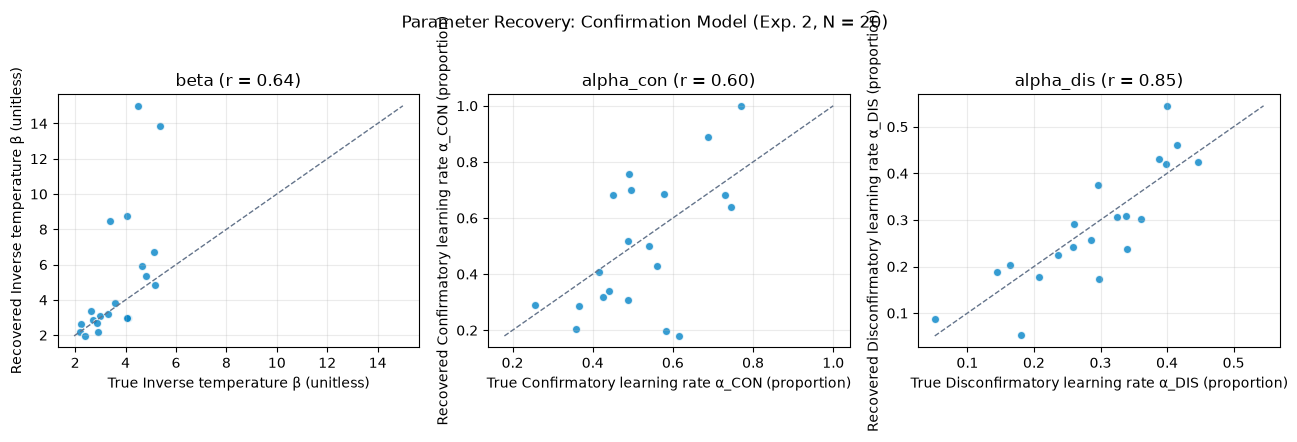

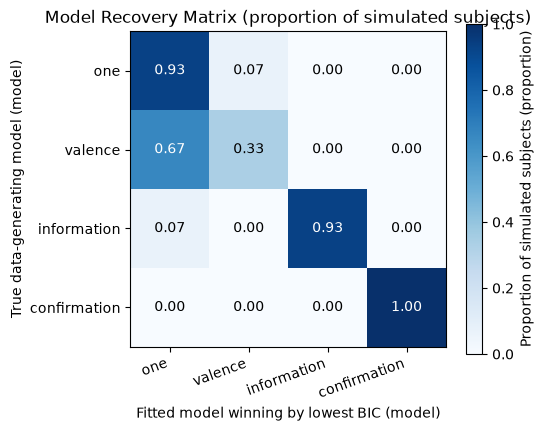

In [7]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models import RLParams
from src.simulate import simulate_cohort
from src.recovery import run_parameter_recovery, run_model_recovery

rng = np.random.default_rng(2026)
n_subjects = 20

# Sample varied true parameters so correlations are meaningful
true_betas = rng.uniform(1.5, 5.5, size=n_subjects)
true_acons = rng.uniform(0.25, 0.80, size=n_subjects)
true_adiss = rng.uniform(0.05, 0.55, size=n_subjects)

true_params_df = pd.DataFrame({
    "participant_id": np.arange(1, n_subjects + 1),
    "beta": true_betas,
    "alpha_con": true_acons,
    "alpha_dis": true_adiss,
})
param_objs = [
    RLParams.from_confirmation(beta=b, alpha_con=ac, alpha_dis=ad)
    for b, ac, ad in zip(true_betas, true_acons, true_adiss)
]

df_rec_sim = simulate_cohort(param_objs, experiment=2, base_seed=900)
df_param_rec = run_parameter_recovery(
    df_sim=df_rec_sim,
    true_params_df=true_params_df,
    model_name="confirmation",
    counterfactual=True,
    n_restarts=2,
)

# Plot Parameter Recovery (True vs. Recovered)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
specs = [
    ("beta", "Inverse temperature β (unitless)"),
    ("alpha_con", "Confirmatory learning rate α_CON (proportion)"),
    ("alpha_dis", "Disconfirmatory learning rate α_DIS (proportion)"),
]
for ax, (col, label) in zip(axes, specs):
    x_true = df_param_rec[f"{col}_true"]
    y_rec = df_param_rec[f"{col}_rec"]
    r_val = np.corrcoef(x_true, y_rec)[0, 1]
    ax.scatter(x_true, y_rec, alpha=0.8, color="#0284c7", edgecolor="white")
    lims = [min(x_true.min(), y_rec.min()), max(x_true.max(), y_rec.max())]
    ax.plot(lims, lims, "--", color="#64748b", linewidth=1)
    ax.set_title(f"{col} (r = {r_val:.2f})")
    ax.set_xlabel(f"True {label}")
    ax.set_ylabel(f"Recovered {label}")
    ax.grid(alpha=0.25)

plt.suptitle("Parameter Recovery: Confirmation Model (Exp. 2, N = 20)", y=1.03)
plt.tight_layout()
fig.savefig(project_root / "figures" / "parameter_recovery.png", dpi=300, bbox_inches="tight")
plt.show()

# Model Recovery across 4 core candidate models
cand_models = ["one", "valence", "information", "confirmation"]
sim_by_model = {
    "one": simulate_cohort(
        [RLParams.from_confirmation(3.0, 0.35, 0.35) for _ in range(15)],
        experiment=2, base_seed=1100
    ),
    "valence": simulate_cohort(
        [RLParams(beta=3.0, alpha_c_pos=0.60, alpha_c_neg=0.15, alpha_u_pos=0.60, alpha_u_neg=0.15) for _ in range(15)],
        experiment=2, base_seed=1200
    ),
    "information": simulate_cohort(
        [RLParams(beta=3.0, alpha_c_pos=0.55, alpha_c_neg=0.55, alpha_u_pos=0.15, alpha_u_neg=0.15) for _ in range(15)],
        experiment=2, base_seed=1300
    ),
    "confirmation": simulate_cohort(
        [RLParams.from_confirmation(3.0, 0.60, 0.15) for _ in range(15)],
        experiment=2, base_seed=1400
    ),
}

df_mod_rec = run_model_recovery(sim_by_model, cand_models, counterfactual=True, n_restarts=2)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(df_mod_rec.values, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(cand_models)))
ax.set_yticks(range(len(cand_models)))
ax.set_xticklabels(cand_models, rotation=20, ha="right")
ax.set_yticklabels(cand_models)
ax.set_xlabel("Fitted model winning by lowest BIC (model)")
ax.set_ylabel("True data-generating model (model)")
ax.set_title("Model Recovery Matrix (proportion of simulated subjects)")
for i in range(len(cand_models)):
    for j in range(len(cand_models)):
        val = df_mod_rec.values[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="white" if val > 0.5 else "black")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Proportion of simulated subjects (proportion)")
plt.tight_layout()
fig.savefig(project_root / "figures" / "model_recovery.png", dpi=300, bbox_inches="tight")
plt.show()